In [1]:
# Import Library
import pandas as pd
import re
import string
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [2]:
import pandas as pd
# Load Dataset
data = pd.read_csv('../review_gopay_newest_sort.csv')
text_column = "content"

print("Ukuran dataset:", data.shape)
print("Daftar Kolom:", data.columns.tolist())
print("Jumlah data:", len(data))

data[[text_column]].head(10)


Ukuran dataset: (123253, 6)
Daftar Kolom: ['userName', 'content', 'score', 'thumbsUpCount', 'reviewCreatedVersion', 'at']
Jumlah data: 123253


,content
0,Mantap
1,Bagus dan mudah digunakan
2,Good
3,Sangat membantu orang menengah mantap semoga s...
4,Ga ribet .. Sukaaaa
5,Sangat membantu
6,Mantap pakay gopay
7,mantap mantap mantap
8,Layanan sang Mudah Dan Sangat Memuaskan
9,Berbisnis


C:\Users\ASUS\AppData\Local\Temp\ipykernel_10380\2270519300.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data_raw, x='score', palette='viridis')


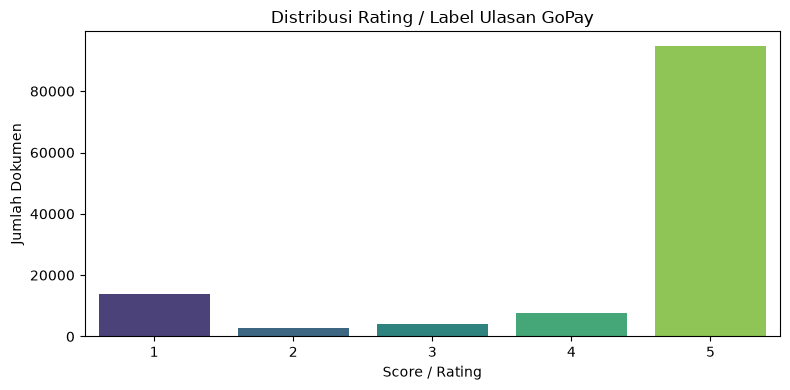

In [3]:
# Visualisasi Distribusi Label (score)
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset asli untuk mendapatkan kolom score
data_raw = pd.read_csv('../review_gopay_newest_sort.csv')

plt.figure(figsize=(8, 4))
sns.countplot(data=data_raw, x='score', palette='viridis')
plt.title('Distribusi Rating / Label Ulasan GoPay')
plt.xlabel('Score / Rating')
plt.ylabel('Jumlah Dokumen')
plt.tight_layout()
plt.show()

In [4]:
# Case Folding

#Mengubah seluruh teks menjadi huruf kecil (lowercase):
def case_folding(text):
    return str(text).lower()

# Contoh
text = "Saya Belajar NLP"
print(case_folding(text))
# Output: saya belajar nlp

saya belajar nlp


In [5]:
# Menghapus URL
def remove_url(text):
    return re.sub(r"http\S+|www\S+", "", text)

# Contoh
text = "Kunjungi https://example.com sekarang"
print(remove_url(text))

Kunjungi  sekarang


In [6]:
# Menghapus Mention
def remove_mention(text):
    return re.sub(r"@\w+", "", text)

# Contoh
text = "@user1 produk ini bagus"
print(remove_mention(text))

 produk ini bagus


In [7]:
# Menghapus Hashtag
def remove_hashtag(text):
    return re.sub(r"#\w+", "", text)

# Contoh
text = "Aplikasi ini bagus #GoPay"
print(remove_hashtag(text))

Aplikasi ini bagus 


In [8]:
# Menghapus Angka
def remove_number(text):
    return re.sub(r"\d+", "", text)

# Contoh
text = "Harga Rp.50.000"
print(remove_number(text))

Harga Rp..


In [9]:
# Menghapus Punctuation
def remove_punctuation(text):
    return text.translate(
        str.maketrans("", "", string.punctuation)
    )

# contoh
text = "Bagus banget!!!"
print(remove_punctuation(text))

Bagus banget


In [10]:
# Membersihkan Whitespace
def clean_whitespace(text):
    return re.sub(r"\s+", " ", text).strip()

# contoh
text = "  GoPay    sangat   bagus  "
print(clean_whitespace(text))


GoPay sangat bagus


In [11]:
# Fungsi Cleaning Lengkap

# Gabungkan semua fungsi menjadi satu pipeline:
def clean_text(text):
    text = str(text)
    text = text.lower()           # case folding
     # Cleaning
    text = remove_url(text)       # hapus URL
    text = remove_mention(text)   # hapus mention
    text = remove_hashtag(text)   # hapus hashtag
    text = remove_number(text)    # hapus angka
    text = remove_punctuation(text)  # hapus punctuation
    text = clean_whitespace(text) # bersihkan whitespace
    return text

# Menerapkan ke dataset
text_column = "content"  
data["clean_text"] = data[text_column].apply(clean_text)

data[[text_column, "clean_text"]].head(10)

,content,clean_text
0,Mantap,mantap
1,Bagus dan mudah digunakan,bagus dan mudah digunakan
2,Good,good
3,Sangat membantu orang menengah mantap semoga s...,sangat membantu orang menengah mantap semoga s...
4,Ga ribet .. Sukaaaa,ga ribet sukaaaa
5,Sangat membantu,sangat membantu
6,Mantap pakay gopay,mantap pakay gopay
7,mantap mantap mantap,mantap mantap mantap
8,Layanan sang Mudah Dan Sangat Memuaskan,layanan sang mudah dan sangat memuaskan
9,Berbisnis,berbisnis


In [12]:
# Stopword Removal
stop_words = set(stopwords.words("indonesian"))

def remove_stopwords(tokens):
    return [
        token for token in tokens
        if token not in stop_words
    ]

# Contoh
tokens = ["saya", "sedang", "belajar", "nlp", "yang", "menarik"]
print(remove_stopwords(tokens))

['belajar', 'nlp', 'menarik']


In [13]:
import pandas as pd

data = pd.read_csv('../review_gopay_newest_sort.csv')
text_column = "content"

# Stemming dengan Sastrawi
factory = StemmerFactory()
stemmer = factory.create_stemmer()

def stem_tokens(tokens):
    return [stemmer.stem(token) for token in tokens]

# Contoh
text = "Mahasiswa sedang mempelajari pemrograman."
print(stemmer.stem(text))

mahasiswa sedang ajar pemrograman


In [14]:
# Pipeline Preprocessing

def preprocessing_pipeline(text):
    # 1. Cleaning
    text = clean_text(text)

    # 2. Tokenization
    tokens = word_tokenize(text)

    # 3. Stopword Removal
    tokens = remove_stopwords(tokens)

    # 4. Stemming
    tokens = stem_tokens(tokens)

    return tokens

# Menerapkan preprocessing secara bertahap
import time

text_column = "content"
batch_size = 200
processed_tokens = []

start_time = time.time()

for start in range(0, len(data), batch_size):
    end = min(start + batch_size, len(data))

    batch = data[text_column].iloc[start:end]
    hasil = batch.apply(preprocessing_pipeline)

    processed_tokens.extend(hasil.tolist())

    print(f"Data {end} dari {len(data)} selesai diproses")

# Menyimpan hasil tokenisasi dan preprocessing
data["processed_tokens"] = processed_tokens

print("\nPreprocessing selesai!")
print(f"Waktu proses: {time.time() - start_time:.2f} detik")

# Menampilkan 10 hasil pertama
print(data[["content", "processed_tokens"]].head(10))

# Menerapkan ke dataset
data["processed_tokens"] = data[text_column].apply(preprocessing_pipeline)
print(data[["content", "processed_tokens"]].head(10))



Data 200 dari 123253 selesai diproses
Data 400 dari 123253 selesai diproses
Data 600 dari 123253 selesai diproses
Data 800 dari 123253 selesai diproses
Data 1000 dari 123253 selesai diproses
Data 1200 dari 123253 selesai diproses
Data 1400 dari 123253 selesai diproses
Data 1600 dari 123253 selesai diproses
Data 1800 dari 123253 selesai diproses
Data 2000 dari 123253 selesai diproses
Data 2200 dari 123253 selesai diproses
Data 2400 dari 123253 selesai diproses
Data 2600 dari 123253 selesai diproses
Data 2800 dari 123253 selesai diproses
Data 3000 dari 123253 selesai diproses
Data 3200 dari 123253 selesai diproses
Data 3400 dari 123253 selesai diproses
Data 3600 dari 123253 selesai diproses
Data 3800 dari 123253 selesai diproses
Data 4000 dari 123253 selesai diproses
Data 4200 dari 123253 selesai diproses
Data 4400 dari 123253 selesai diproses
Data 4600 dari 123253 selesai diproses
Data 4800 dari 123253 selesai diproses
Data 5000 dari 123253 selesai diproses
Data 5200 dari 123253 selesai

In [15]:
#  Menggabungkan Token Kembali
data["processed_text"] = data["processed_tokens"].apply(
    lambda tokens: " ".join(tokens)
)

# Menampilkan hasil preprocessing
print(data[["content", "processed_tokens", "processed_text"]].head(10))

                                             content  \
0                                             Mantap   
1                          Bagus dan mudah digunakan   
2                                               Good   
3  Sangat membantu orang menengah mantap semoga s...   
4                                Ga ribet .. Sukaaaa   
5                                    Sangat membantu   
6                                 Mantap pakay gopay   
7                               mantap mantap mantap   
8            Layanan sang Mudah Dan Sangat Memuaskan   
9                                          Berbisnis   

                                    processed_tokens  \
0                                           [mantap]   
1                                     [bagus, mudah]   
2                                             [good]   
3  [bantu, orang, tengah, mantap, moga, sukses, g...   
4                               [ga, ribet, sukaaaa]   
5                                            [b

In [21]:
# Perbandingan Raw vs Processed
for i in range(5):
    print("RAW:")
    print(data.iloc[i][text_column])

    print("\nPROCESSED:")
    print(data.iloc[i]["processed_text"])

    print("=" * 80)

RAW:
Mantap

PROCESSED:
mantap
RAW:
Bagus dan mudah digunakan

PROCESSED:
bagus mudah
RAW:
Good

PROCESSED:
good
RAW:
Sangat membantu orang menengah mantap semoga sukses terus gopay

PROCESSED:
bantu orang tengah mantap moga sukses gopay
RAW:
Ga ribet .. Sukaaaa

PROCESSED:
ga ribet sukaaaa


In [17]:
# Menyimpan Dataset Hasil Preprocessing
output_columns = [text_column, "clean_text", "processed_text"]

data[["content", "processed_text"]].to_csv(
    "dataset_preprocessed.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset berhasil disimpan!")

Dataset berhasil disimpan!


In [25]:
# TUGAS EKSPERIMEN
hasil = data[[text_column]].head(20).copy()
hasil["lowercase"] = hasil[text_column].apply(case_folding)
hasil["cleaning"] = hasil[text_column].apply(clean_text)
hasil["tokenisasi"] = hasil["cleaning"].apply(word_tokenize)
hasil["stopword"] = hasil["tokenisasi"].apply(
    remove_stopwords
)
hasil["stemming"] = hasil["stopword"].apply(stem_tokens)
hasil["stemming"] = hasil["stemming"].apply(
    lambda tokens: " ".join(tokens)
)
hasil.columns = [
    "Raw Text",
    "Setelah Lowercase",
    "Setelah Cleaning",
    "Setelah Tokenisasi",
    "Setelah Stopword",
    "Setelah Stemming"
]
hasil

,Raw Text,Setelah Lowercase,Setelah Cleaning,Setelah Tokenisasi,Setelah Stopword,Setelah Stemming
0,Mantap,mantap,mantap,[mantap],[mantap],mantap
1,Bagus dan mudah digunakan,bagus dan mudah digunakan,bagus dan mudah digunakan,"[bagus, dan, mudah, digunakan]","[bagus, mudah]",bagus mudah
2,Good,good,good,[good],[good],good
3,Sangat membantu orang menengah mantap semoga s...,sangat membantu orang menengah mantap semoga s...,sangat membantu orang menengah mantap semoga s...,"[sangat, membantu, orang, menengah, mantap, se...","[membantu, orang, menengah, mantap, semoga, su...",bantu orang tengah mantap moga sukses gopay
4,Ga ribet .. Sukaaaa,ga ribet .. sukaaaa,ga ribet sukaaaa,"[ga, ribet, sukaaaa]","[ga, ribet, sukaaaa]",ga ribet sukaaaa
5,Sangat membantu,sangat membantu,sangat membantu,"[sangat, membantu]",[membantu],bantu
6,Mantap pakay gopay,mantap pakay gopay,mantap pakay gopay,"[mantap, pakay, gopay]","[mantap, pakay, gopay]",mantap pakay gopay
7,mantap mantap mantap,mantap mantap mantap,mantap mantap mantap,"[mantap, mantap, mantap]","[mantap, mantap, mantap]",mantap mantap mantap
8,Layanan sang Mudah Dan Sangat Memuaskan,layanan sang mudah dan sangat memuaskan,layanan sang mudah dan sangat memuaskan,"[layanan, sang, mudah, dan, sangat, memuaskan]","[layanan, sang, mudah, memuaskan]",layan sang mudah muas
9,Berbisnis,berbisnis,berbisnis,[berbisnis],[berbisnis],bisnis


In [24]:
import os
import pandas as pd

file_final = "dataset_preprocessed.csv"

print("File ditemukan:", os.path.exists(file_final))

if os.path.exists(file_final):
    cek = pd.read_csv(file_final, low_memory=False)
    print("Jumlah baris:", len(cek))
    print("Kolom tersedia:", cek.columns.tolist())
    display(cek[["content", "processed_text"]].head(5))

File ditemukan: True


Jumlah baris: 123253
Kolom tersedia: ['content', 'processed_text']


,content,processed_text
0,Mantap,mantap
1,Bagus dan mudah digunakan,bagus mudah
2,Good,good
3,Sangat membantu orang menengah mantap semoga s...,bantu orang tengah mantap moga sukses gopay
4,Ga ribet .. Sukaaaa,ga ribet sukaaaa
